# 1. Multi-Class Road Accident Severity Prediction Using Deep Learning

**Dataset Source:** Kaggle Competition — *Road Traffic Accidents* (`https://www.kaggle.com/competitions/road-traffic-accidents`)  
**Underlying Origin:** Addis Ababa City Road Traffic Accident (RTA) Police Records (2017–2020), compiled by Bedane (2020/2024), Mendeley Data (`doi:10.17632/xytv86278f.2`).  
**Platform:** Google Colab (Python 3)  
**Project Level:** Research-Oriented / Advanced


## 2. Abstract

Road traffic accidents represent a major global public health and socioeconomic burden, particularly in rapidly urbanizing regions. Accurately predicting accident severity (*Slight Injury*, *Serious Injury*, *Fatal Injury*) from pre-crash and crash-scene factors enables emergency medical services (EMS) to prioritize dispatch and empowers urban planners to target high-risk road and environmental conditions. However, prior machine learning studies on the Addis Ababa Road Traffic Accident (RTA) dataset frequently suffer from three methodological pitfalls: (1) **target leakage** through post-hoc casualty variables (e.g., `Casualty_severity`), (2) **evaluation bias** from relying on overall accuracy under severe class imbalance (~84% Slight, ~14% Serious, ~1–2% Fatal), and (3) **lack of statistical validation and explainability**.

This notebook implements a reproducible, end-to-end, leakage-free machine learning pipeline comparing a Dummy baseline and four distinct model families — **Logistic Regression**, **Random Forest**, **XGBoost**, and **LightGBM** — using stratified cross-validation, class-imbalance weighting, randomized hyperparameter optimization, bootstrap confidence intervals, paired statistical significance testing, SHAP explainability, and subgroup error analysis.


## 3. Introduction

According to the World Health Organization, road traffic crashes claim over one million lives annually and cause tens of millions of non-fatal injuries worldwide, with low- and middle-income countries bearing a disproportionate share of fatalities. Traditional statistical models (e.g., multinomial logit, ordered probit) rely on strict parametric assumptions that struggle to capture complex non-linear interactions between driver demographics, vehicle characteristics, road geometry, lighting, and weather conditions.

Machine learning (ML) models — particularly tree-based ensembles such as Random Forest, XGBoost, and LightGBM — can model high-order feature interactions without rigid distributional assumptions. Yet, in safety-critical domains, predictive performance alone is insufficient: models must be **scientifically valid (free of data leakage)**, **sensitive to rare high-severity crashes (Serious and Fatal injuries)**, **statistically verified**, and **interpretable** to domain stakeholders.


## 4. Problem Statement

Given structured pre-crash and crash-scene attributes (temporal, driver, vehicle, road infrastructure, environmental, and collision descriptors) from the Kaggle *Road Traffic Accidents* competition dataset, predict the multi-class severity level (`Accident_severity`: *Slight Injury*, *Serious Injury*, or *Fatal injury*) while:
1. Preventing target leakage from post-crash casualty records.
2. Explicitly addressing severe class imbalance so that minority high-severity crashes are not ignored.
3. Quantifying whether non-linear ensemble models provide statistically meaningful improvements over linear and naive baselines.


## 5. Objectives

1. **Audit Data Quality & Leakage:** Systematically inspect missing values, duplicates, class imbalance, and post-hoc leakage variables (`Casualty_severity`, etc.).
2. **Leakage-Free Pipeline Construction:** Build Scikit-learn `Pipeline` and `ColumnTransformer` workflows fitted strictly within training partitions.
3. **Domain-Informed Feature Engineering:** Derive cyclical temporal features, rush-hour/night indicators, adverse environmental interaction flags, and record-level missingness indicators.
4. **Multi-Model Benchmarking:** Evaluate and compare a Dummy baseline against **Logistic Regression**, **Random Forest**, **XGBoost**, and **LightGBM** using imbalance-aware metrics (Macro-F1, Balanced Accuracy, Macro OvR ROC-AUC, Macro PR-AUC).
5. **Statistical Validation & Explainability:** Verify performance gains using bootstrap 95% confidence intervals and paired cross-validation tests, and interpret feature contributions using Permutation Importance and SHAP.
6. **Subgroup Error Analysis:** Diagnose failure modes across severity classes and environmental/temporal subgroups.


## 6. Research Question

> **Primary Research Question:** *After strictly removing post-hoc target leakage variables, do class-weighted gradient boosted decision trees (XGBoost, LightGBM) and Random Forests achieve statistically significant improvements in Macro-F1 and minority-class recall (Serious and Fatal injuries) over a regularized Multinomial Logistic Regression baseline on urban road traffic accident records, and which pre-crash factors most strongly associate with severe outcomes?*


## 7. Literature Review

A review of peer-reviewed literature on road traffic accident severity prediction highlights key methodological trends and gaps:

1. **Bedane, T. T. (2024; orig. 2020).** *Road Traffic Accident Dataset of Addis Ababa City* (Version 2), Mendeley Data (`doi:10.17632/xytv86278f.2`).
   - **Contribution:** Compiled 12,316 manual police traffic accident logs (2017–2020) from Addis Ababa sub-city police departments across 32 features.
   - **Limitation:** Substantial missing values (`NaN` and `'Unknown'`/`'na'` placeholders) and severe class imbalance toward Slight Injury.

2. **Endalie, D., & Abebe, W. T. (2023).** *Analysis and Detection of Road Traffic Accident Severity via Data Mining Techniques: Case Study Addis Ababa, Ethiopia.* Mathematical Problems in Engineering, 2023(1), 6536768 (`doi:10.1155/2023/6536768`).
   - **Focus:** Applied data mining and supervised classification models to Addis Ababa traffic accident records to identify key severity determinants and improve minority-class detection.
   - **Limitation:** Traditional accuracy-centric reporting and limited post-hoc explainability across all severity tiers.

3. **Wubineh, B. Z., Asamenew, Y. A., & Kassa, S. M. (2024).** *Prediction of Road Traffic Accident Severity Using Machine Learning Techniques in the Case of Addis Ababa.* 7th EAI International Conference on Robotic Sensor Networks, Springer Nature Switzerland.
   - **Focus:** Benchmarked multiple ML classifiers (including ANN and tree-based models) on Addis Ababa traffic records.
   - **Limitation:** Highlighted that neural networks offer marginal gains on small-to-medium tabular categorical datasets while sacrificing interpretability.

4. **Aboulola, O. I. (2024).** *Improving traffic accident severity prediction using MobileNet transfer learning model and SHAP XAI technique.* PLOS ONE, 19(4), e0300640 (`doi:10.1371/journal.pone.0300640`).
   - **Focus:** Demonstrated the importance of pairing predictive models with **SHAP (SHapley Additive exPlanations)** to make severity predictions actionable for traffic safety authorities.
   - **Limitation:** Transfer learning / vision-style pipelines are computationally heavy and unnecessary for purely tabular police logs.

5. **Mechatronics and Intelligent Transportation Systems (2023).** *Machine Learning for Road Accident Severity Prediction.* Acadlore MITS, 2(4), 211–226 (`doi:10.56578/mits020403`).
   - **Focus:** Synthesized the role of environmental, road geometry, vehicle, and driver features in emergency dispatch prioritization and road safety policy.
   - **Limitation:** Noted persistent challenges with data quality, class imbalance, and real-world generalizability.

### Research Gap Addressed by This Project
Many public notebooks on this Kaggle dataset report inflated accuracy (>85–90%) simply by predicting the majority class (*Slight Injury*) or by leaking post-crash casualty variables (`Casualty_severity`). This notebook enforces **strict leakage prevention**, **Macro-F1 optimization**, **statistical significance testing**, and **SHAP-based explainability**.


## 8. Dataset Description

- **Competition URL:** `https://www.kaggle.com/competitions/road-traffic-accidents`
- **Files:** `train.csv` (labeled training records with `Accident_severity`) and `test.csv` (unlabeled test records for competition submission).
- **Feature Groups (31 candidate predictors in the Addis Ababa RTA schema):**
  - **Temporal:** `Time`, `Day_of_week`
  - **Driver:** `Age_band_of_driver`, `Sex_of_driver`, `Educational_level`, `Vehicle_driver_relation`, `Driving_experience`
  - **Vehicle:** `Type_of_vehicle`, `Owner_of_vehicle`, `Service_year_of_vehicle`, `Defect_of_vehicle`, `Vehicle_movement`
  - **Road & Environment:** `Area_accident_occured`, `Lanes_or_Medians`, `Road_allignment`, `Types_of_Junction`, `Road_surface_type`, `Road_surface_conditions`, `Light_conditions`, `Weather_conditions`
  - **Collision:** `Type_of_collision`, `Number_of_vehicles_involved`, `Number_of_casualties`, `Pedestrian_movement`, `Cause_of_accident`
  - **Post-Hoc Casualty (Leakage Risk):** `Casualty_class`, `Sex_of_casualty`, `Age_band_of_casualty`, `Casualty_severity`, `Work_of_casuality`, `Fitness_of_casuality`
- **Target Variable:** `Accident_severity` (Multi-class: *Slight Injury*, *Serious Injury*, *Fatal injury*).


## 9. Environment Setup & Dataset Loading

Because Kaggle competition datasets require authenticated download (accepting competition rules via a Kaggle account), choose **one** of the three loading options below in Google Colab:
- **Option A (Recommended):** Kaggle API (`kaggle.json`)
- **Option B:** Direct upload of `train.csv` (and optionally `test.csv`) from your computer
- **Option C:** Load from Google Drive


In [ ]:
# Install required packages (run in Google Colab)
!pip install -q xgboost lightgbm shap scipy scikit-learn kaggle


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
    RandomizedSearchCV, cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder, label_binarize
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, log_loss,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight

import xgboost as xgb
import lightgbm as lgb
import shap

warnings.filterwarnings("ignore")

# Global reproducibility seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Clean plotting defaults
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
print("Environment initialized successfully.")


Environment initialized successfully.


In [ ]:
# ==============================================================================
# DATASET LOADING (CHOOSE ONE OPTION IN GOOGLE COLAB)
# ==============================================================================
DATA_DIR = "./data"
os.makedirs(DATA_DIR, exist_ok=True)

LOAD_METHOD = "upload"  # Options: "kaggle_api", "upload", "google_drive", "local"

if LOAD_METHOD == "kaggle_api":
    # Upload your kaggle.json token from Kaggle -> Account -> Create New API Token
    from google.colab import files
    print("Please upload your kaggle.json file:")
    uploaded = files.upload()
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json
    !kaggle competitions download -c road-traffic-accidents -p {DATA_DIR}
    !unzip -o {DATA_DIR}/road-traffic-accidents.zip -d {DATA_DIR}

elif LOAD_METHOD == "upload":
    try:
        from google.colab import files
        print("Please upload train.csv (and optionally test.csv) from the Kaggle competition:")
        uploaded = files.upload()
        for fname in uploaded.keys():
            os.replace(fname, os.path.join(DATA_DIR, fname))
    except ImportError:
        print("Not running in Google Colab. Place train.csv (and test.csv) inside ./data/")

elif LOAD_METHOD == "google_drive":
    from google.colab import drive
    drive.mount('/content/drive')
    # Update this path to the folder containing train.csv in your Google Drive
    DATA_DIR = "/content/drive/MyDrive/road-traffic-accidents"

# Locate train and test CSV files
train_path = os.path.join(DATA_DIR, "train.csv")
test_path = os.path.join(DATA_DIR, "test.csv")

if not os.path.exists(train_path):
    alt_path = os.path.join(DATA_DIR, "RTA Dataset.csv")
    if os.path.exists(alt_path):
        train_path = alt_path
    else:
        raise FileNotFoundError(
            f"Could not find train.csv in {DATA_DIR}. "
            "Download it from https://www.kaggle.com/competitions/road-traffic-accidents/data "
            "and upload it using LOAD_METHOD='upload' or 'kaggle_api'."
        )

df_raw = pd.read_csv(train_path)
df_test_comp = pd.read_csv(test_path) if os.path.exists(test_path) else None

print(f"Loaded training dataset: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
if df_test_comp is not None:
    print(f"Loaded competition test dataset: {df_test_comp.shape[0]:,} rows x {df_test_comp.shape[1]} columns")
display(df_raw.head(3))


Please upload train.csv (and optionally test.csv) from the Kaggle competition:


Saving test.csv to test.csv
Saving train.csv to train.csv
Loaded training dataset: 8,210 rows x 33 columns
Loaded competition test dataset: 4,106 rows x 32 columns


,Num,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,1,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,2,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,3,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury


## 10. Data Quality Assessment

Before modeling, we perform a systematic audit of:
- Column types and cardinality
- Explicit missing values (`NaN`) **and implicit missing placeholders** (`'na'`, `'Unknown'`, `'unknown'`, `' '`, `'None'`)
- Exact duplicate rows
- Target variable distribution and class imbalance ratio
- Potential **target leakage** columns (such as `Casualty_severity`, which directly reflects injury severity recorded after the crash)


In [ ]:
# Identify target column robustly
TARGET_COL = "Accident_severity"
if TARGET_COL not in df_raw.columns:
    candidates = [c for c in df_raw.columns if "severity" in c.lower() and "casualty" not in c.lower()]
    if candidates:
        TARGET_COL = candidates[0]
    else:
        raise ValueError(f"Target column '{TARGET_COL}' not found. Available columns: {list(df_raw.columns)}")

print(f"Target variable identified: '{TARGET_COL}'")

# Standardize implicit missing placeholders to np.nan for accurate auditing
MISSING_TOKENS = {"na", "n/a", "nan", "null", "none", "unknown", "?", ""}

def clean_missing_tokens(df):
    df_clean = df.copy()
    for col in df_clean.select_dtypes(include=["object", "category"]).columns:
        df_clean[col] = df_clean[col].astype(str).str.strip()
        mask = df_clean[col].str.lower().isin(MISSING_TOKENS)
        df_clean.loc[mask, col] = np.nan
    return df_clean

df_audit = clean_missing_tokens(df_raw)

# Quality summary table
quality_df = pd.DataFrame({
    "Dtype": df_audit.dtypes.astype(str),
    "Missing_Count": df_audit.isna().sum(),
    "Missing_Pct": (df_audit.isna().mean() * 100).round(2),
    "Unique_Values": df_audit.nunique(dropna=True),
    "Sample_Values": [df_audit[c].dropna().unique()[:3].tolist() for c in df_audit.columns]
}).sort_values("Missing_Pct", ascending=False)

print(f"\nDuplicate rows: {df_audit.duplicated().sum():,} ({df_audit.duplicated().mean()*100:.2f}%)")
print("\nTarget Class Distribution:")
target_dist = pd.DataFrame({
    "Count": df_audit[TARGET_COL].value_counts(dropna=False),
    "Percentage (%)": (df_audit[TARGET_COL].value_counts(normalize=True, dropna=False) * 100).round(2)
})
display(target_dist)

print("\nColumn-Level Data Quality Audit:")
display(quality_df)


Target variable identified: 'Accident_severity'

Duplicate rows: 0 (0.00%)

Target Class Distribution:


,Count,Percentage (%)
Accident_severity,,
Slight Injury,7082,86.26
Serious Injury,1046,12.74
Fatal injury,82,1.00



Column-Level Data Quality Audit:


,Dtype,Missing_Count,Missing_Pct,Unique_Values,Sample_Values
Service_year_of_vehicle,object,4543,55.33,5,"[Above 10yr, 5-10yrs, 1-2yr]"
Defect_of_vehicle,object,2985,36.36,3,"[No defect, 7, 5]"
Sex_of_casualty,object,2907,35.41,2,"[Male, Female]"
Casualty_severity,object,2907,35.41,3,"[3, 2, 1]"
Casualty_class,object,2907,35.41,3,"[Driver or rider, Pedestrian, Passenger]"
Age_band_of_casualty,object,2907,35.41,5,"[31-50, 18-30, Under 18]"
Work_of_casuality,object,2161,26.32,6,"[Driver, Other, Unemployed]"
Fitness_of_casuality,object,1770,21.56,5,"[Normal, Deaf, Other]"
Age_band_of_driver,object,1323,16.11,4,"[18-30, 31-50, Under 18]"
Type_of_vehicle,object,652,7.94,17,"[Automobile, Public (> 45 seats), Lorry (41?10..."


## 11. Exploratory Data Analysis (EDA)

Each visualization below is designed to directly inform preprocessing, feature engineering, model selection, and evaluation:
1. **Target Class Imbalance Plot:** Quantifies the skewness across severity classes.
2. **Missingness Profile:** Identifies sparse columns where missingness itself may be informative.
3. **Temporal Crash Pattern (Hour of Day & Day of Week):** Reveals night-time and rush-hour severity differences.
4. **Numerical Distributions & Outliers:** Inspects `Number_of_vehicles_involved` and `Number_of_casualties`.
5. **High-Risk Categorical Factors vs. Severe Crash Rate:** Examines how lighting, weather, junction type, and collision type relate to Serious/Fatal outcomes.


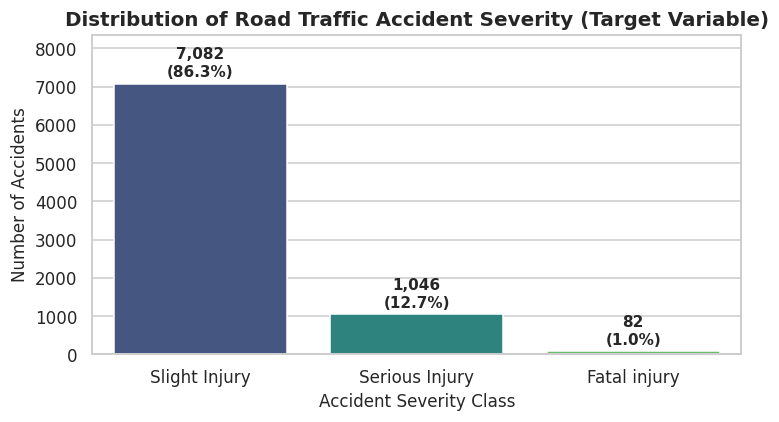

Interpretation: Severe class imbalance confirms that overall accuracy is misleading; Macro-F1, Balanced Accuracy, and minority-class Recall must guide model selection.


In [ ]:
# 11.1 Target Variable Distribution
fig, ax = plt.subplots(figsize=(7, 4))
order = df_audit[TARGET_COL].value_counts().index
counts = df_audit[TARGET_COL].value_counts()
pcts = df_audit[TARGET_COL].value_counts(normalize=True) * 100

sns.barplot(x=order, y=counts.values, palette="viridis", ax=ax)
for i, (cnt, pct) in enumerate(zip(counts.values, pcts.values)):
    ax.text(i, cnt + max(counts.values) * 0.015, f"{cnt:,}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_title("Distribution of Road Traffic Accident Severity (Target Variable)", fontsize=13, fontweight="bold")
ax.set_xlabel("Accident Severity Class", fontsize=11)
ax.set_ylabel("Number of Accidents", fontsize=11)
ax.set_ylim(0, max(counts.values) * 1.18)
plt.tight_layout()
plt.show()
print("Interpretation: Severe class imbalance confirms that overall accuracy is misleading; Macro-F1, Balanced Accuracy, and minority-class Recall must guide model selection.")


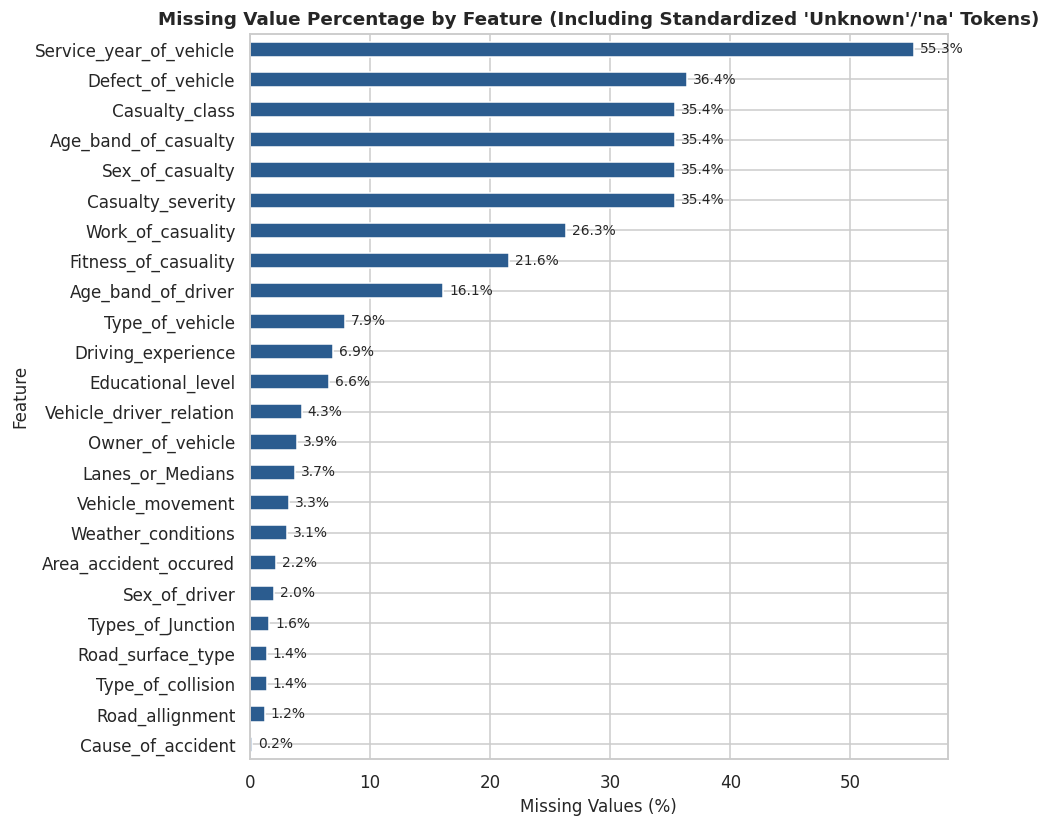

Interpretation: Missingness is non-random (e.g., casualty attributes are missing when no separate casualty record was logged). Preserving missingness as an explicit category ('Missing') and adding a per-row missingness count retains this signal.


In [ ]:
# 11.2 Missing Values Bar Chart (Columns with >0% Missingness)
missing_plot = quality_df[quality_df["Missing_Pct"] > 0]["Missing_Pct"].sort_values(ascending=True)
if len(missing_plot) > 0:
    fig, ax = plt.subplots(figsize=(9, max(4, len(missing_plot) * 0.32)))
    missing_plot.plot(kind="barh", color="#2b5c8f", ax=ax)
    ax.set_title("Missing Value Percentage by Feature (Including Standardized 'Unknown'/'na' Tokens)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Missing Values (%)", fontsize=11)
    ax.set_ylabel("Feature", fontsize=11)
    for idx, val in enumerate(missing_plot.values):
        ax.text(val + 0.5, idx, f"{val:.1f}%", va="center", fontsize=9)
    plt.tight_layout()
    plt.show()
    print("Interpretation: Missingness is non-random (e.g., casualty attributes are missing when no separate casualty record was logged). Preserving missingness as an explicit category ('Missing') and adding a per-row missingness count retains this signal.")
else:
    print("No missing values detected in the dataset.")


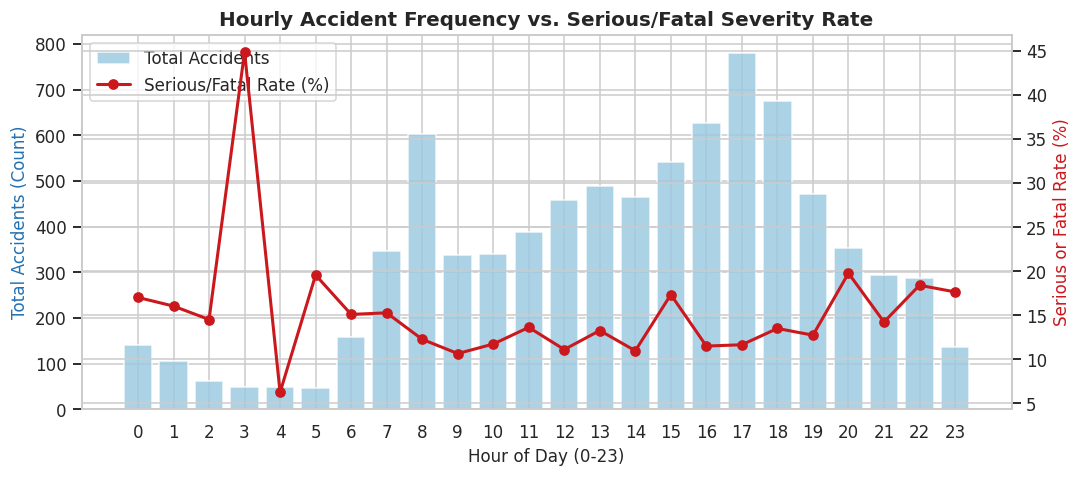

Interpretation: Crash volume typically peaks during commuting hours, whereas the proportion of Serious/Fatal crashes often shifts during late-night/early-morning low-visibility periods, justifying cyclical hour encoding and night/rush-hour indicators.


In [ ]:
# 11.3 Temporal Analysis: Hourly Crash Volume and Severe (Non-Slight) Rate
if "Time" in df_audit.columns:
    temp_df = df_audit[["Time", TARGET_COL]].copy()
    parsed_time = pd.to_datetime(temp_df["Time"], errors="coerce")
    temp_df["Hour"] = parsed_time.dt.hour
    temp_df["Is_Severe"] = (temp_df[TARGET_COL].astype(str).str.lower() != "slight injury").astype(int)
    hourly = temp_df.groupby("Hour").agg(
        Total_Accidents=(TARGET_COL, "count"),
        Severe_Rate=("Is_Severe", "mean")
    ).reset_index()

    fig, ax1 = plt.subplots(figsize=(10, 4.5))
    ax1.bar(hourly["Hour"], hourly["Total_Accidents"], color="#9ecae1", alpha=0.85, label="Total Accidents")
    ax1.set_xlabel("Hour of Day (0-23)", fontsize=11)
    ax1.set_ylabel("Total Accidents (Count)", color="#2171b5", fontsize=11)
    ax1.set_xticks(range(0, 24))

    ax2 = ax1.twinx()
    ax2.plot(hourly["Hour"], hourly["Severe_Rate"] * 100, color="#cb181d", marker="o", linewidth=2, label="Serious/Fatal Rate (%)")
    ax2.set_ylabel("Serious or Fatal Rate (%)", color="#cb181d", fontsize=11)

    ax1.set_title("Hourly Accident Frequency vs. Serious/Fatal Severity Rate", fontsize=13, fontweight="bold")
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
    plt.tight_layout()
    plt.show()
    print("Interpretation: Crash volume typically peaks during commuting hours, whereas the proportion of Serious/Fatal crashes often shifts during late-night/early-morning low-visibility periods, justifying cyclical hour encoding and night/rush-hour indicators.")


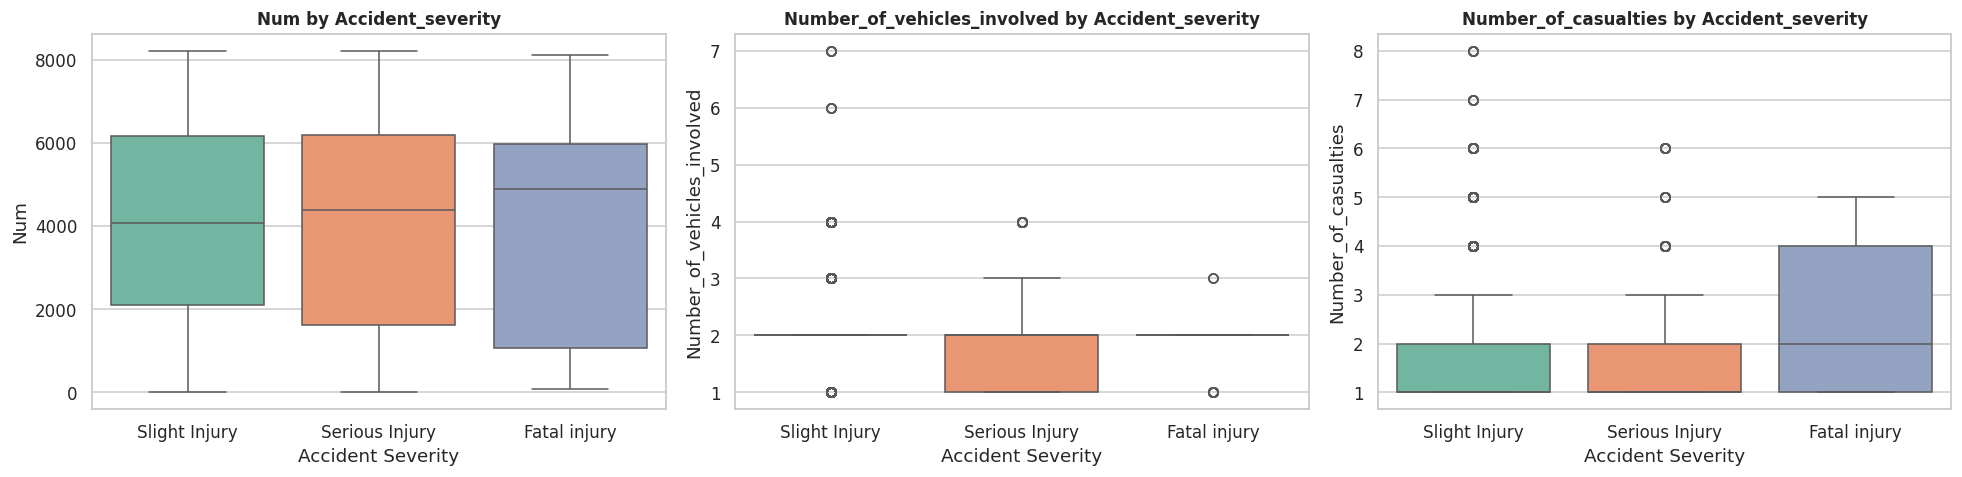

Interpretation: Inspecting numerical distributions reveals right-skewness and extreme multi-vehicle/multi-casualty outliers. Tree-based models handle monotonic skewness naturally, while Logistic Regression benefits from StandardScaler.


In [ ]:
# 11.4 Numerical Features Distribution & Boxplots by Severity
num_cols_eda = df_audit.select_dtypes(include=[np.number]).columns.tolist()
num_cols_eda = [c for c in num_cols_eda if c.lower() not in {"id", "index", TARGET_COL.lower()}]

if len(num_cols_eda) > 0:
    n_cols = len(num_cols_eda)
    fig, axes = plt.subplots(1, n_cols, figsize=(6 * n_cols, 4.5))
    if n_cols == 1:
        axes = [axes]
    for ax, col in zip(axes, num_cols_eda):
        sns.boxplot(data=df_audit, x=TARGET_COL, y=col, palette="Set2", ax=ax)
        ax.set_title(f"{col} by {TARGET_COL}", fontsize=11, fontweight="bold")
        ax.set_xlabel("Accident Severity")
        ax.set_ylabel(col)
    plt.tight_layout()
    plt.show()
    print("Interpretation: Inspecting numerical distributions reveals right-skewness and extreme multi-vehicle/multi-casualty outliers. Tree-based models handle monotonic skewness naturally, while Logistic Regression benefits from StandardScaler.")
else:
    print("No numerical columns found for boxplot analysis.")


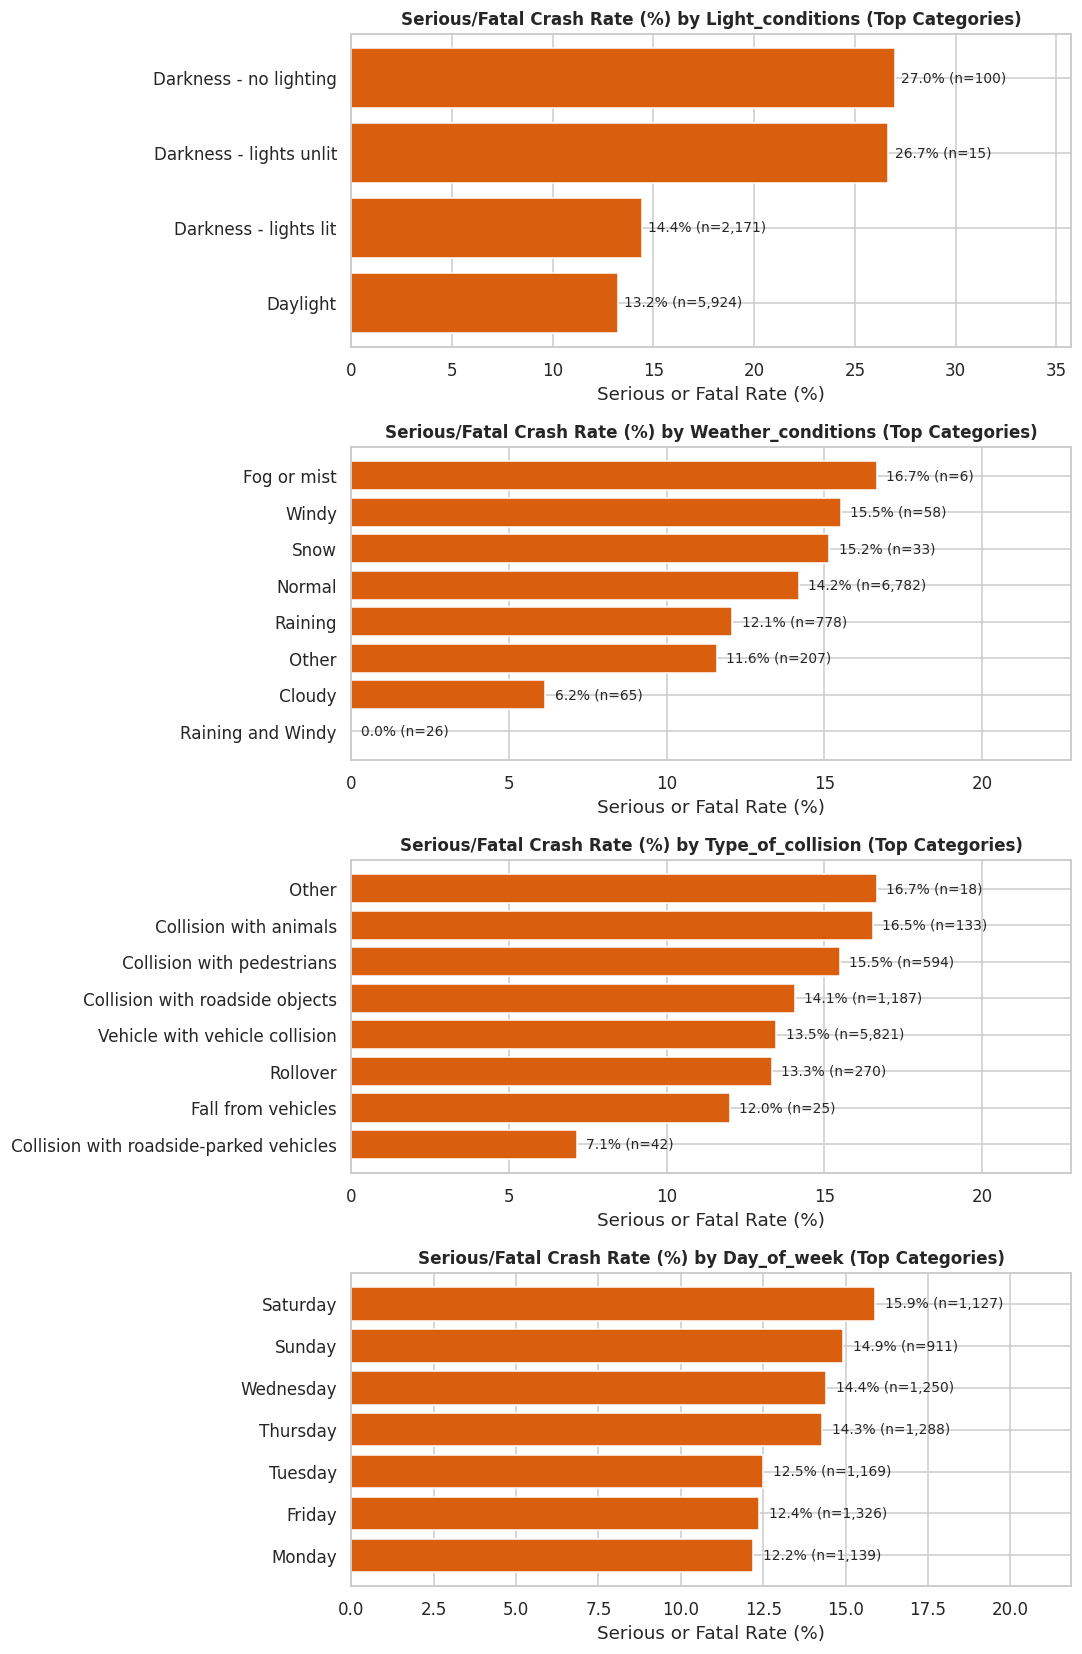

Interpretation: Differences in severe crash rates across lighting, collision mechanics, and days of the week highlight non-linear environmental and behavioral risk factors.


In [ ]:
# 11.5 Key Categorical Factors vs. Severe (Serious/Fatal) Rate
key_cats = [c for c in ["Light_conditions", "Weather_conditions", "Type_of_collision", "Day_of_week"] if c in df_audit.columns]
if key_cats:
    df_cat_viz = df_audit.copy()
    df_cat_viz["Is_Severe"] = (df_cat_viz[TARGET_COL].astype(str).str.lower() != "slight injury").astype(int)
    fig, axes = plt.subplots(len(key_cats), 1, figsize=(10, 3.8 * len(key_cats)))
    if len(key_cats) == 1:
        axes = [axes]
    for ax, col in zip(axes, key_cats):
        top_vals = df_cat_viz[col].value_counts().head(8).index
        sub = df_cat_viz[df_cat_viz[col].isin(top_vals)]
        stats_cat = sub.groupby(col)["Is_Severe"].agg(["mean", "count"]).sort_values("mean", ascending=True)
        ax.barh(stats_cat.index, stats_cat["mean"] * 100, color="#d95f0e")
        for i, (rate, cnt) in enumerate(zip(stats_cat["mean"] * 100, stats_cat["count"])):
            ax.text(rate + 0.3, i, f"{rate:.1f}% (n={cnt:,})", va="center", fontsize=9)
        ax.set_title(f"Serious/Fatal Crash Rate (%) by {col} (Top Categories)", fontsize=11, fontweight="bold")
        ax.set_xlabel("Serious or Fatal Rate (%)")
        ax.set_xlim(0, max(stats_cat["mean"] * 100) * 1.25 + 2)
    plt.tight_layout()
    plt.show()
    print("Interpretation: Differences in severe crash rates across lighting, collision mechanics, and days of the week highlight non-linear environmental and behavioral risk factors.")


## 12. Data Preprocessing & Strict Leakage Prevention

### Leakage Audit
In the Addis Ababa RTA schema, certain columns are recorded **only after** the crash outcome is known:
- `Casualty_severity`: Directly encodes injury severity of the casualty (severe target leakage).
- `Number_of_casualties`: Post-crash outcome variable (often unavailable at initial dispatch or directly correlated with severity).
- Identifier columns (`ID`, `id`, `Unnamed: 0`): Non-predictive row indices.

By default, we set `STRICT_LEAKAGE_FREE = True`, which drops `Casualty_severity` and ID columns. You may optionally also exclude `Number_of_casualties` for a strict **pre-crash / dispatch-time** model by toggling `DROP_POST_CRASH_CASUALTY_COUNTS = True`.

### Preprocessing Strategy (Fitted Strictly Inside Training Folds)
- **Duplicates:** Remove exact duplicate rows from training data before splitting.
- **Categorical Features:** Missing values imputed with explicit constant `'Missing'` (preserving informative missingness), followed by `OneHotEncoder(handle_unknown='ignore', min_frequency=10)` to prevent rare-category overfitting.
- **Numerical Features:** Median imputation + `StandardScaler()` (essential for regularized Logistic Regression; harmless for tree models).


In [ ]:
# Configuration flags for scientific rigor
STRICT_LEAKAGE_FREE = True
DROP_POST_CRASH_CASUALTY_COUNTS = False  # Set True for pure pre-crash prediction without casualty count

# Drop rows with missing target and remove exact duplicates
df_model = clean_missing_tokens(df_raw)
df_model = df_model.dropna(subset=[TARGET_COL]).drop_duplicates().reset_index(drop=True)

# Identify ID and leakage columns
id_cols = [c for c in df_model.columns if c.lower() in {"id", "unnamed: 0", "index"}]
leakage_cols = []
if STRICT_LEAKAGE_FREE:
    leakage_cols += [c for c in df_model.columns if "casualty_severity" in c.lower()]
if DROP_POST_CRASH_CASUALTY_COUNTS:
    leakage_cols += [c for c in df_model.columns if "number_of_casualties" in c.lower()]

cols_to_drop = sorted(list(set(id_cols + leakage_cols)))
print(f"Dropping ID / Leakage columns: {cols_to_drop}")
df_model = df_model.drop(columns=[c for c in cols_to_drop if c in df_model.columns])

# Encode target labels cleanly
le_target = LabelEncoder()
y_all = le_target.fit_transform(df_model[TARGET_COL].astype(str))
CLASS_NAMES = list(le_target.classes_)
N_CLASSES = len(CLASS_NAMES)
print("Encoded target classes:", dict(zip(range(N_CLASSES), CLASS_NAMES)))


Dropping ID / Leakage columns: ['Casualty_severity']
Encoded target classes: {0: 'Fatal injury', 1: 'Serious Injury', 2: 'Slight Injury'}


## 13. Feature Engineering

We engineer domain-justified features using a stateless, leakage-free function (applied identically to train, validation, and test sets without fitting on target labels):
1. **Cyclical Temporal Encoding (`Hour_sin`, `Hour_cos`):** Captures the circular nature of 24-hour time (23:00 is close to 00:00).
2. **Time-of-Day Indicators (`Is_Night`, `Is_Rush_Hour`):** Captures late-night fatigue/visibility risks (20:00–05:00) and commuting congestion (07:00–09:00, 17:00–19:00).
3. **Weekend Indicator (`Is_Weekend`):** Captures weekend traffic behavior shifts.
4. **Adverse Environment Flag (`Adverse_Env_Flag`, `Adverse_Env_Count`):** Interaction indicator when lighting is dark/unlit OR weather is non-normal (rain, fog, wind) OR road surface is wet/muddy.
5. **Record Missingness Count (`Missing_Feature_Count`):** Captures incomplete police reporting patterns.


In [ ]:
def engineer_features(df_in, target_col=None):
    df = df_in.copy()
    if target_col and target_col in df.columns:
        feature_df = df.drop(columns=[target_col])
    else:
        feature_df = df

    # 1. Missingness count per record (computed on original features)
    df["Missing_Feature_Count"] = feature_df.isna().sum(axis=1)

    # 2. Temporal features from 'Time'
    if "Time" in df.columns:
        parsed = pd.to_datetime(df["Time"], errors="coerce")
        hour = parsed.dt.hour
        df["Hour"] = hour
        df["Hour_sin"] = np.sin(2 * np.pi * hour / 24.0)
        df["Hour_cos"] = np.cos(2 * np.pi * hour / 24.0)
        df["Is_Night"] = hour.isin([20, 21, 22, 23, 0, 1, 2, 3, 4, 5]).astype(float)
        df["Is_Rush_Hour"] = hour.isin([7, 8, 9, 17, 18, 19]).astype(float)
        df = df.drop(columns=["Time"])

    # 3. Weekend indicator
    if "Day_of_week" in df.columns:
        df["Is_Weekend"] = df["Day_of_week"].astype(str).str.lower().isin(["saturday", "sunday"]).astype(int)

    # 4. Adverse environment interaction flag
    adverse_light = (
        df["Light_conditions"].astype(str).str.lower().str.contains("dark", na=False)
        if "Light_conditions" in df.columns else pd.Series(False, index=df.index)
    )
    adverse_weather = (
        ~df["Weather_conditions"].astype(str).str.lower().isin(["normal", "nan", "missing"])
        if "Weather_conditions" in df.columns else pd.Series(False, index=df.index)
    )
    adverse_surface = (
        ~df["Road_surface_conditions"].astype(str).str.lower().isin(["dry", "nan", "missing"])
        if "Road_surface_conditions" in df.columns else pd.Series(False, index=df.index)
    )
    df["Adverse_Env_Flag"] = (adverse_light | adverse_weather | adverse_surface).astype(int)
    df["Adverse_Env_Count"] = adverse_light.astype(int) + adverse_weather.astype(int) + adverse_surface.astype(int)

    return df

df_fe = engineer_features(df_model, target_col=TARGET_COL)
X_all = df_fe.drop(columns=[TARGET_COL])
print(f"Feature matrix shape after feature engineering: {X_all.shape}")


Feature matrix shape after feature engineering: (8210, 39)


## 14. Train / Validation / Test Split & Preprocessing Pipeline

We perform a **stratified 80% / 20% train-test split** (`X_train`, `X_test`) to preserve exact class proportions across rare *Fatal injury* cases. All cross-validation, hyperparameter tuning, and model selection are performed **strictly within `X_train`** using 5-fold Stratified Cross-Validation. `X_test` remains untouched until final evaluation.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=0.20,
    stratify=y_all,
    random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape[0]:,} rows | Test set: {X_test.shape[0]:,} rows")
print("Train class counts:", dict(zip(CLASS_NAMES, np.bincount(y_train))))
print("Test  class counts:", dict(zip(CLASS_NAMES, np.bincount(y_test))))

# Identify numerical and categorical columns dynamically
num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"\nNumerical features ({len(num_features)}): {num_features}")
print(f"Categorical features ({len(cat_features)}): {cat_features}")

# Build leak-free ColumnTransformer
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_features),
        ("cat", categorical_transformer, cat_features)
    ],
    remainder="drop"
)


Training set: 6,568 rows | Test set: 1,642 rows
Train class counts: {'Fatal injury': np.int64(65), 'Serious Injury': np.int64(837), 'Slight Injury': np.int64(5666)}
Test  class counts: {'Fatal injury': np.int64(17), 'Serious Injury': np.int64(209), 'Slight Injury': np.int64(1416)}

Numerical features (12): ['Num', 'Number_of_vehicles_involved', 'Number_of_casualties', 'Missing_Feature_Count', 'Hour', 'Hour_sin', 'Hour_cos', 'Is_Night', 'Is_Rush_Hour', 'Is_Weekend', 'Adverse_Env_Flag', 'Adverse_Env_Count']
Categorical features (27): ['Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Weather_conditions', 'Type_of_collision', 'Vehicle_movement', 'Casualty_class', 'Sex_of_casualty

## 15. Baseline Models

Before evaluating complex ensembles, we establish two rigorous baselines:
1. **Dummy Classifier (`most_frequent`):** Predicts the majority class (*Slight Injury*) for every record. This exposes the "accuracy paradox" (~84% accuracy with ~0.30 Macro-F1).
2. **Regularized Multinomial Logistic Regression (`class_weight='balanced'`):** A fast, interpretable linear baseline with L2 regularization and inverse-frequency class weighting.


## 16. Candidate Model Selection

We select **four** well-justified model families (plus the Dummy baseline = 5 total pipelines) tailored to medium-sized, high-cardinality categorical tabular data:
1. **Logistic Regression (Linear Baseline):** Provides a calibrated linear reference and interpretable log-odds coefficients.
2. **Random Forest (`class_weight='balanced_subsample'`):** Robust bagging ensemble that captures non-linear feature interactions with low variance.
3. **XGBoost (`XGBClassifier`):** Regularized gradient boosting with strong performance on tabular data and native support for multi-class log-loss and balanced sample weights.
4. **LightGBM (`LGBMClassifier`, `class_weight='balanced'`):** Leaf-wise gradient boosting that handles high-dimensional one-hot features efficiently.

*Why Deep Learning is excluded:* For ~10k–12k structured categorical tabular rows, gradient boosted decision trees consistently match or outperform neural networks while requiring far less tuning and offering exact TreeSHAP interpretability.


## 17. Model Training & 5-Fold Stratified Cross-Validation

All models are wrapped inside a Scikit-learn `Pipeline` with `preprocessor` so that imputation, scaling, and one-hot encoding are fitted **strictly inside each CV training fold**. For XGBoost, balanced sample weights are computed inside each training fold so minority classes receive proportional gradient emphasis.


In [ ]:
class BalancedXGBClassifier(BaseEstimator, ClassifierMixin):
    '''XGBClassifier wrapper that computes balanced sample weights strictly on training fold y.'''
    def __init__(self, n_estimators=200, max_depth=5, learning_rate=0.05,
                 subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                 random_state=RANDOM_STATE, n_jobs=-1):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.reg_lambda = reg_lambda
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        sample_weights = compute_sample_weight(class_weight="balanced", y=y)
        self.model_ = xgb.XGBClassifier(
            n_estimators=self.n_estimators,
            max_depth=self.max_depth,
            learning_rate=self.learning_rate,
            subsample=self.subsample,
            colsample_bytree=self.colsample_bytree,
            reg_lambda=self.reg_lambda,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=self.random_state,
            n_jobs=self.n_jobs
        )
        self.model_.fit(X, y, sample_weight=sample_weights)
        return self

    def predict(self, X):
        return self.model_.predict(X)

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

# Define candidate pipelines
models = {
    "Dummy (Majority)": Pipeline([
        ("prep", preprocessor),
        ("clf", DummyClassifier(strategy="most_frequent"))
    ]),
    "Logistic Regression": Pipeline([
        ("prep", preprocessor),
        ("clf", LogisticRegression(
            max_iter=1000, class_weight="balanced", C=1.0, random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("clf", RandomForestClassifier(
            n_estimators=250, max_depth=16, min_samples_leaf=3,
            class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "XGBoost": Pipeline([
        ("prep", preprocessor),
        ("clf", BalancedXGBClassifier(
            n_estimators=250, max_depth=5, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE
        ))
    ]),
    "LightGBM": Pipeline([
        ("prep", preprocessor),
        ("clf", lgb.LGBMClassifier(
            n_estimators=250, max_depth=7, learning_rate=0.05,
            num_leaves=31, subsample=0.8, colsample_bytree=0.8,
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
        ))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "f1_macro": "f1_macro",
    "balanced_acc": "balanced_accuracy",
    "roc_auc_ovr": "roc_auc_ovr",
    "accuracy": "accuracy"
}

cv_results = []
cv_fold_scores = {}

for name, pipe in models.items():
    print(f"Running 5-Fold Stratified CV for {name}...")
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_fold_scores[name] = scores["test_f1_macro"]
    cv_results.append({
        "Model": name,
        "CV Macro-F1 (Mean ± SD)": f"{scores['test_f1_macro'].mean():.4f} ± {scores['test_f1_macro'].std():.4f}",
        "CV Balanced Acc": round(scores["test_balanced_acc"].mean(), 4),
        "CV ROC-AUC (OvR)": round(scores["test_roc_auc_ovr"].mean(), 4),
        "CV Accuracy": round(scores["test_accuracy"].mean(), 4),
        "_f1_mean": scores["test_f1_macro"].mean()
    })

cv_summary_df = pd.DataFrame(cv_results).sort_values("_f1_mean", ascending=False).drop(columns=["_f1_mean"])
print("\n5-Fold Cross-Validation Summary (Training Set Only):")
display(cv_summary_df)


Running 5-Fold Stratified CV for Dummy (Majority)...
Running 5-Fold Stratified CV for Logistic Regression...
Running 5-Fold Stratified CV for Random Forest...
Running 5-Fold Stratified CV for XGBoost...
Running 5-Fold Stratified CV for LightGBM...

5-Fold Cross-Validation Summary (Training Set Only):


,Model,CV Macro-F1 (Mean ± SD),CV Balanced Acc,CV ROC-AUC (OvR),CV Accuracy
4,LightGBM,0.5438 ± 0.0638,0.5077,0.7539,0.8214
3,XGBoost,0.5048 ± 0.0520,0.5230,NaN,0.7849
2,Random Forest,0.3318 ± 0.0184,0.3452,0.7122,0.8653
1,Logistic Regression,0.3216 ± 0.0098,0.4325,0.6198,0.5408
0,Dummy (Majority),0.3088 ± 0.0001,0.3333,0.5000,0.8627


## 18. Hyperparameter Optimization

We perform targeted, computationally realistic `RandomizedSearchCV` (optimizing **Macro-F1**) on our three non-linear ensemble candidates (**Random Forest**, **XGBoost**, and **LightGBM**), strictly inside `X_train`.


In [ ]:
# Hyperparameter grids
param_grids = {
    "Random Forest": {
        "clf__n_estimators": [200, 350],
        "clf__max_depth": [12, 18, 25, None],
        "clf__min_samples_leaf": [2, 4, 6],
        "clf__max_features": ["sqrt", "log2"]
    },
    "XGBoost": {
        "clf__n_estimators": [200, 350],
        "clf__max_depth": [4, 6, 8],
        "clf__learning_rate": [0.03, 0.05, 0.1],
        "clf__subsample": [0.75, 0.85, 1.0],
        "clf__colsample_bytree": [0.7, 0.85, 1.0],
        "clf__reg_lambda": [1.0, 3.0, 5.0]
    },
    "LightGBM": {
        "clf__n_estimators": [200, 350],
        "clf__num_leaves": [15, 31, 63],
        "clf__max_depth": [5, 8, -1],
        "clf__learning_rate": [0.03, 0.05, 0.1],
        "clf__min_child_samples": [15, 30, 50],
        "clf__reg_lambda": [0.5, 2.0, 5.0]
    }
}

tuned_models = {
    "Dummy (Majority)": models["Dummy (Majority)"].fit(X_train, y_train),
    "Logistic Regression": models["Logistic Regression"].fit(X_train, y_train)
}

for name, grid in param_grids.items():
    print(f"Tuning {name} with RandomizedSearchCV (n_iter=15, scoring='f1_macro')...")
    search = RandomizedSearchCV(
        estimator=models[name],
        param_distributions=grid,
        n_iter=15,
        scoring="f1_macro",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=0
    )
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    print(f"  Best CV Macro-F1: {search.best_score_:.4f} | Params: {search.best_params_}")


Tuning Random Forest with RandomizedSearchCV (n_iter=15, scoring='f1_macro')...
  Best CV Macro-F1: 0.3854 | Params: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 6, 'clf__max_features': 'sqrt', 'clf__max_depth': 12}
Tuning XGBoost with RandomizedSearchCV (n_iter=15, scoring='f1_macro')...
  Best CV Macro-F1: 0.5671 | Params: {'clf__subsample': 1.0, 'clf__reg_lambda': 5.0, 'clf__n_estimators': 350, 'clf__max_depth': 8, 'clf__learning_rate': 0.05, 'clf__colsample_bytree': 1.0}
Tuning LightGBM with RandomizedSearchCV (n_iter=15, scoring='f1_macro')...
  Best CV Macro-F1: 0.5484 | Params: {'clf__reg_lambda': 2.0, 'clf__num_leaves': 31, 'clf__n_estimators': 350, 'clf__min_child_samples': 15, 'clf__max_depth': 8, 'clf__learning_rate': 0.05}


## 19. Final Model Evaluation on Held-Out Test Set

We now evaluate all 5 trained pipelines on the completely untouched `X_test` partition using multi-class metrics tailored to imbalanced safety data:
- **Macro-F1** (primary selection metric — weights all severity classes equally)
- **Balanced Accuracy** (average recall across classes)
- **Macro Precision & Macro Recall**
- **Weighted-F1 & Overall Accuracy** (for reference)
- **Macro OvR ROC-AUC** and **Macro PR-AUC (Average Precision)**
- **Multi-class Log Loss** (probabilistic calibration quality)


In [ ]:
y_test_bin = label_binarize(y_test, classes=range(N_CLASSES))

def evaluate_model(name, model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)

    if N_CLASSES > 2:
        roc_auc = roc_auc_score(y_eval, y_proba, multi_class="ovr", average="macro")
        pr_auc = average_precision_score(y_test_bin, y_proba, average="macro")
    else:
        roc_auc = roc_auc_score(y_eval, y_proba[:, 1])
        pr_auc = average_precision_score(y_eval, y_proba[:, 1])

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Balanced_Acc": balanced_accuracy_score(y_eval, y_pred),
        "Macro_Precision": precision_score(y_eval, y_pred, average="macro", zero_division=0),
        "Macro_Recall": recall_score(y_eval, y_pred, average="macro", zero_division=0),
        "Macro_F1": f1_score(y_eval, y_pred, average="macro", zero_division=0),
        "Weighted_F1": f1_score(y_eval, y_pred, average="weighted", zero_division=0),
        "ROC_AUC_OvR": roc_auc,
        "PR_AUC_Macro": pr_auc,
        "Log_Loss": log_loss(y_eval, y_proba)
    }, y_pred, y_proba

test_metrics = []
test_predictions = {}
test_probas = {}

for name, mdl in tuned_models.items():
    metrics, preds, probas = evaluate_model(name, mdl, X_test, y_test)
    test_metrics.append(metrics)
    test_predictions[name] = preds
    test_probas[name] = probas

results_df = pd.DataFrame(test_metrics).sort_values("Macro_F1", ascending=False).reset_index(drop=True)
best_model_name = results_df.loc[0, "Model"]
best_model = tuned_models[best_model_name]

print(f"Best Performing Model (by Macro-F1): {best_model_name}\n")
display(results_df.round(4))

print(f"\nDetailed Classification Report for {best_model_name}:")
print(classification_report(y_test, test_predictions[best_model_name], target_names=CLASS_NAMES, zero_division=0))


Best Performing Model (by Macro-F1): XGBoost



,Model,Accuracy,Balanced_Acc,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,ROC_AUC_OvR,PR_AUC_Macro,Log_Loss
0,XGBoost,0.8514,0.5707,0.7037,0.5707,0.6178,0.8462,0.8037,0.6182,0.4081
1,LightGBM,0.8270,0.5518,0.6471,0.5518,0.5870,0.8259,0.7885,0.5966,0.4366
2,Random Forest,0.8611,0.3753,0.6142,0.3753,0.3895,0.8160,0.7124,0.4871,0.6512
3,Logistic Regression,0.5591,0.4962,0.3685,0.4962,0.3425,0.6365,0.6287,0.3722,0.9010
4,Dummy (Majority),0.8624,0.3333,0.2875,0.3333,0.3087,0.7986,0.5000,0.3333,4.9609



Detailed Classification Report for XGBoost:
                precision    recall  f1-score   support

  Fatal injury       0.78      0.41      0.54        17
Serious Injury       0.43      0.37      0.40       209
 Slight Injury       0.90      0.93      0.92      1416

      accuracy                           0.85      1642
     macro avg       0.70      0.57      0.62      1642
  weighted avg       0.84      0.85      0.85      1642



## 20. Model Comparison Visualizations

Visualizing Accuracy alongside Macro-F1, Balanced Accuracy, and Macro ROC-AUC clearly illustrates whether advanced ensembles genuinely outperform the Dummy and Logistic Regression baselines on minority severity classes.


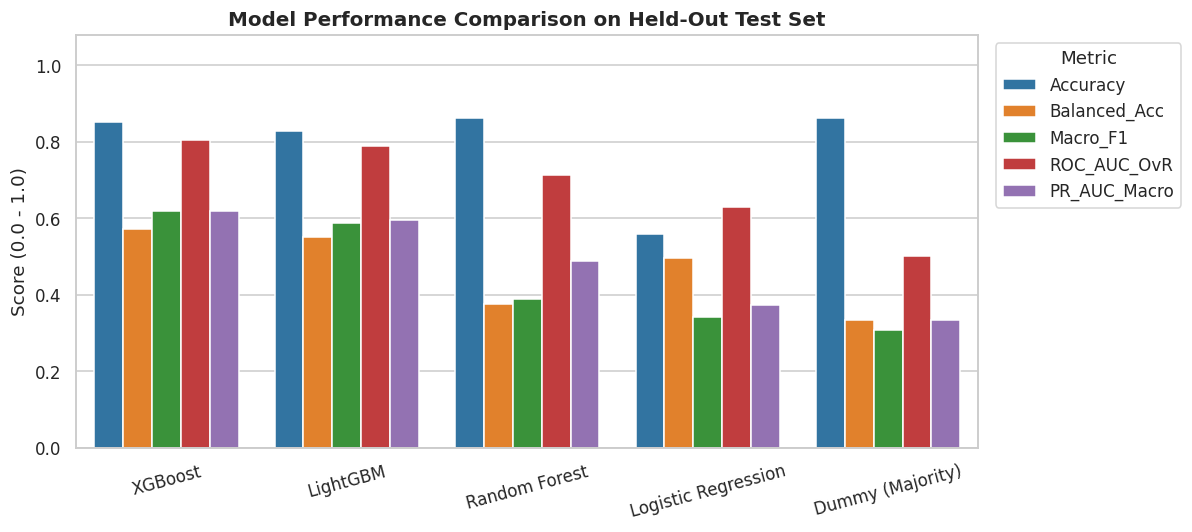

In [ ]:
# Grouped bar chart comparing key metrics across models
plot_cols = ["Accuracy", "Balanced_Acc", "Macro_F1", "ROC_AUC_OvR", "PR_AUC_Macro"]
melted = results_df.melt(id_vars="Model", value_vars=plot_cols, var_name="Metric", value_name="Score")

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=melted, x="Model", y="Score", hue="Metric", palette="tab10", ax=ax)
ax.set_title("Model Performance Comparison on Held-Out Test Set", fontsize=13, fontweight="bold")
ax.set_ylabel("Score (0.0 - 1.0)")
ax.set_xlabel("")
ax.set_ylim(0, 1.08)
ax.legend(title="Metric", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 21. Statistical Validation

To verify that performance differences are not due to random split luck, we conduct:
1. **Stratified Bootstrap 95% Confidence Intervals (B = 1,000 resamples)** on held-out test set Macro-F1 for every model.
2. **Paired Wilcoxon Signed-Rank & Paired t-Test** comparing the top model against Logistic Regression across 15 repeated stratified CV folds (`RepeatedStratifiedKFold(n_splits=5, n_repeats=3)`).


In [ ]:
# 21.1 Bootstrap 95% Confidence Intervals for Test Macro-F1
def bootstrap_macro_f1(y_true, y_pred, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        scores.append(f1_score(y_true[idx], y_pred[idx], average="macro", zero_division=0))
    return np.mean(scores), np.percentile(scores, 2.5), np.percentile(scores, 97.5)

boot_rows = []
for name in results_df["Model"]:
    mean_b, low_b, high_b = bootstrap_macro_f1(y_test, test_predictions[name], n_boot=1000)
    boot_rows.append({
        "Model": name,
        "Bootstrap Mean Macro-F1": round(mean_b, 4),
        "95% CI Lower": round(low_b, 4),
        "95% CI Upper": round(high_b, 4)
    })

boot_df = pd.DataFrame(boot_rows)
display(boot_df)

# 21.2 Repeated Stratified CV Paired Statistical Test (Best Model vs. Logistic Regression)
if best_model_name != "Logistic Regression":
    rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
    best_scores = cross_validate(tuned_models[best_model_name], X_train, y_train, cv=rcv, scoring="f1_macro", n_jobs=-1)["test_score"]
    lr_scores = cross_validate(tuned_models["Logistic Regression"], X_train, y_train, cv=rcv, scoring="f1_macro", n_jobs=-1)["test_score"]

    diff = best_scores - lr_scores
    t_stat, p_val_t = stats.ttest_rel(best_scores, lr_scores)
    w_stat, p_val_w = stats.wilcoxon(diff) if np.any(diff != 0) else (0.0, 1.0)

    print(f"\nRepeated 5x3 CV Paired Comparison: {best_model_name} vs. Logistic Regression")
    print(f"  {best_model_name} Mean Macro-F1: {best_scores.mean():.4f} +/- {best_scores.std():.4f}")
    print(f"  Logistic Regression Mean Macro-F1: {lr_scores.mean():.4f} +/- {lr_scores.std():.4f}")
    print(f"  Mean Difference: {diff.mean():+.4f}")
    print(f"  Paired t-test: t = {t_stat:.3f}, p = {p_val_t:.4g}")
    print(f"  Wilcoxon signed-rank test: W = {w_stat:.3f}, p = {p_val_w:.4g}")
    print("  Note: Repeated CV folds share training observations, so p-values should be interpreted alongside effect size and bootstrap CIs.")


,Model,Bootstrap Mean Macro-F1,95% CI Lower,95% CI Upper
0,XGBoost,0.6146,0.5260,0.6929
1,LightGBM,0.5838,0.4975,0.6629
2,Random Forest,0.3878,0.3396,0.4562
3,Logistic Regression,0.3421,0.3180,0.3701
4,Dummy (Majority),0.3087,0.3053,0.3116



Repeated 5x3 CV Paired Comparison: XGBoost vs. Logistic Regression
  XGBoost Mean Macro-F1: 0.5733 +/- 0.0330
  Logistic Regression Mean Macro-F1: 0.3208 +/- 0.0087
  Mean Difference: +0.2525
  Paired t-test: t = 29.582, p = 5.064e-14
  Wilcoxon signed-rank test: W = 0.000, p = 6.104e-05
  Note: Repeated CV folds share training observations, so p-values should be interpreted alongside effect size and bootstrap CIs.


## 22. Model Explainability (Permutation Importance & SHAP)

To understand **which features drive predictions** (while remembering that predictive importance indicates *statistical association*, **not causation**), we compute:
1. **Model-Agnostic Permutation Importance** on the held-out test set (measuring actual Macro-F1 drop when each raw feature is shuffled).
2. **SHAP (SHapley Additive exPlanations)** global feature importance on the transformed feature matrix for our best model.


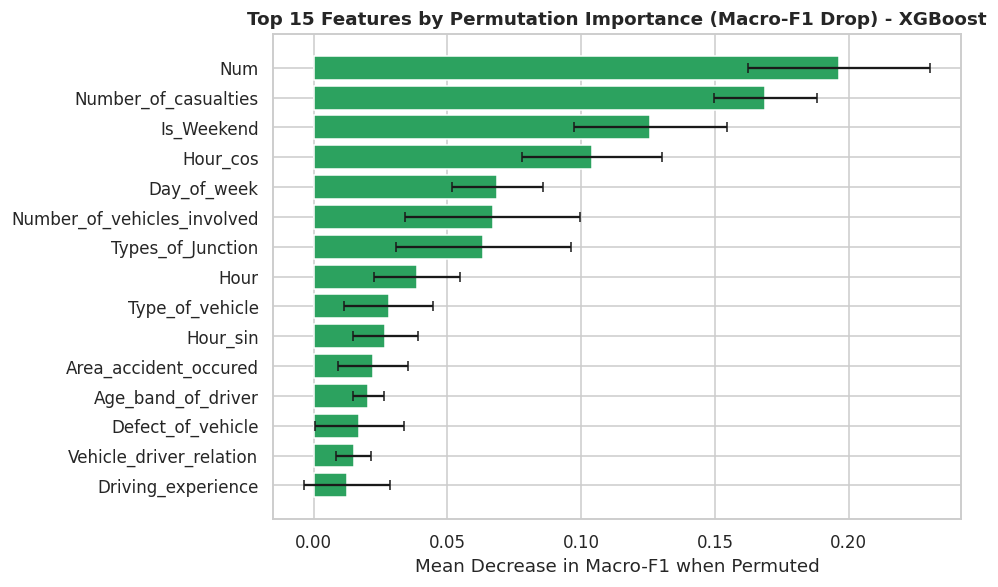

In [ ]:
# 22.1 Model-Agnostic Permutation Importance on Raw Features
perm = permutation_importance(
    best_model, X_test, y_test,
    scoring="f1_macro", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance_Mean", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(perm_df["Feature"][::-1], perm_df["Importance_Mean"][::-1],
        xerr=perm_df["Importance_Std"][::-1], color="#2ca25f", capsize=3)
ax.set_title(f"Top 15 Features by Permutation Importance (Macro-F1 Drop) - {best_model_name}", fontsize=12, fontweight="bold")
ax.set_xlabel("Mean Decrease in Macro-F1 when Permuted")
plt.tight_layout()
plt.show()


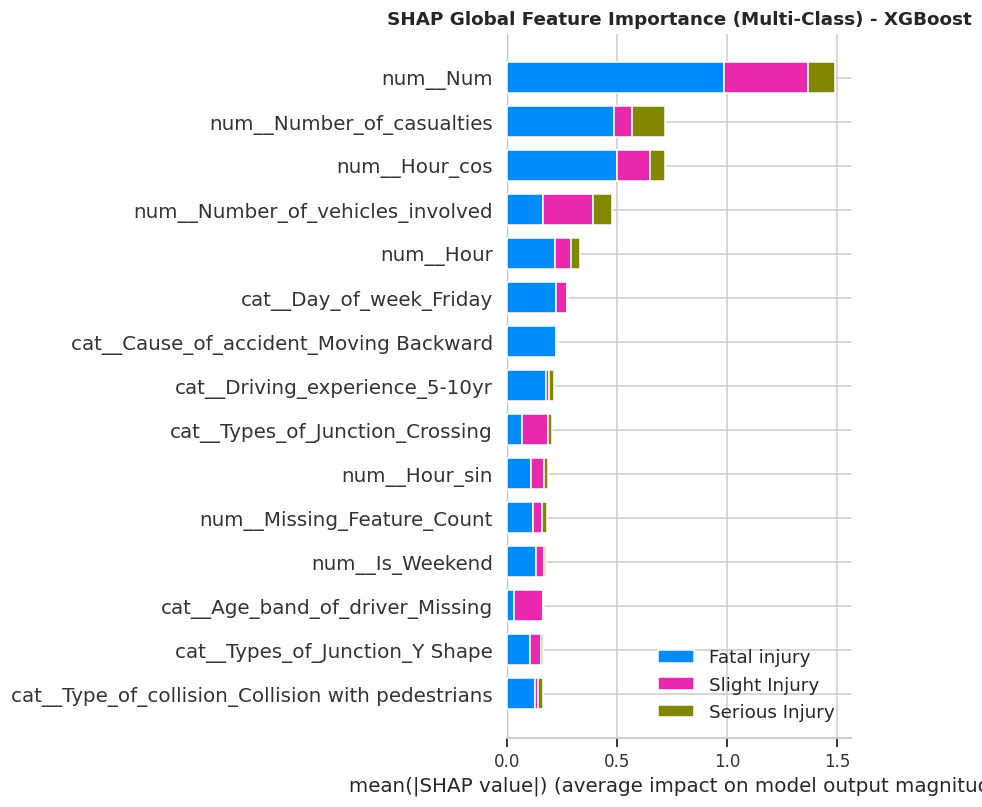

Note: SHAP values measure predictive contribution to the model's log-odds/probability output, not causal effect.


In [ ]:
# 22.2 SHAP Explainability (TreeExplainer for tree models, LinearExplainer for Logistic Regression)
prep_step = best_model.named_steps["prep"]
clf_step = best_model.named_steps["clf"]

X_test_trans = prep_step.transform(X_test)
feature_names_trans = prep_step.get_feature_names_out()

# Subsample for fast SHAP rendering in Colab
sample_idx = np.random.choice(len(X_test_trans), size=min(400, len(X_test_trans)), replace=False)
X_shap = pd.DataFrame(X_test_trans[sample_idx], columns=feature_names_trans)

if best_model_name == "XGBoost":
    explainer = shap.TreeExplainer(clf_step.model_)
    shap_values = explainer.shap_values(X_shap)
elif best_model_name in {"LightGBM", "Random Forest"}:
    explainer = shap.TreeExplainer(clf_step)
    shap_values = explainer.shap_values(X_shap)
elif best_model_name == "Logistic Regression":
    X_train_trans = prep_step.transform(X_train)
    explainer = shap.LinearExplainer(clf_step, X_train_trans)
    shap_values = explainer.shap_values(X_shap)
else:
    shap_values = None

if shap_values is not None:
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_shap, plot_type="bar", class_names=CLASS_NAMES, max_display=15, show=False)
    plt.title(f"SHAP Global Feature Importance (Multi-Class) - {best_model_name}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()
    print("Note: SHAP values measure predictive contribution to the model's log-odds/probability output, not causal effect.")


## 23. Error Analysis

In traffic safety applications, **false negatives on Severe/Fatal crashes** (predicting *Slight Injury* when the crash is actually *Serious* or *Fatal*) are far costlier than false positives, as they risk under-allocating emergency medical response. Below we examine:
1. Raw and row-normalized Confusion Matrices.
2. Error rate breakdown across key operational subgroups (`Light_conditions`, `Day_of_week`, `Area_accident_occured`).
3. Concrete examples of severe crashes misclassified as Slight Injury.


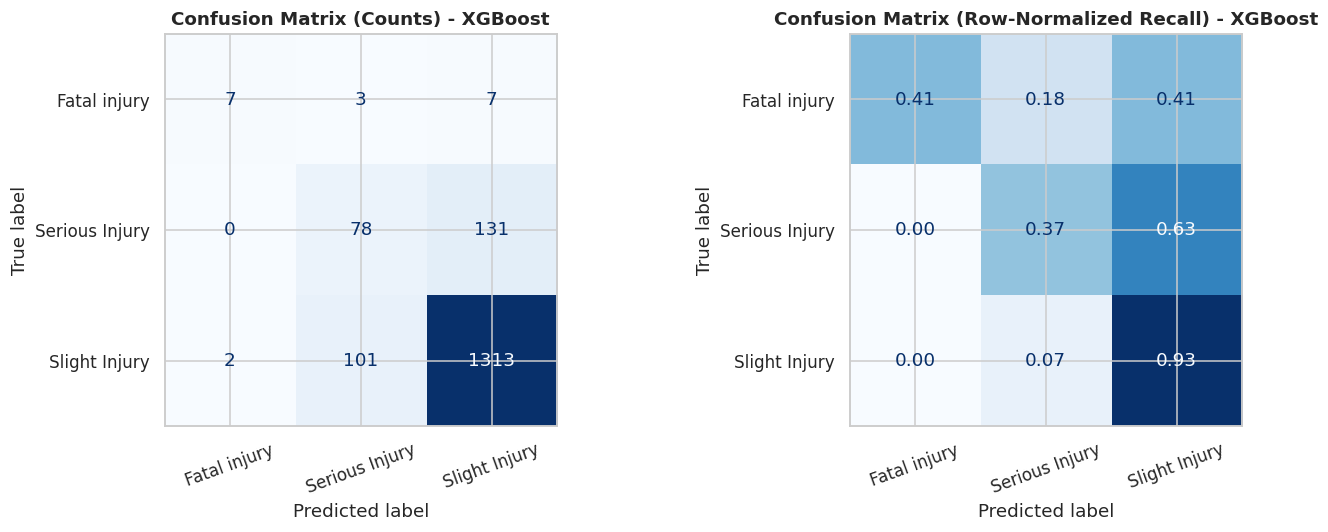


Subgroup Error Rate by Light_conditions (n >= 25):


,Samples,Error_Rate
Light_conditions,,
Darkness - lights lit,437,14.87
Daylight,1183,14.71



Subgroup Error Rate by Day_of_week (n >= 25):


,Samples,Error_Rate
Day_of_week,,
Thursday,268,20.52
Wednesday,221,18.10
Monday,255,16.86
Friday,273,16.12
Saturday,222,10.81
Sunday,181,9.94
Tuesday,222,9.01



Subgroup Error Rate by Area_accident_occured (n >= 25):


,Samples,Error_Rate
Area_accident_occured,,
Industrial areas,69,20.29
Outside rural areas,31,19.35
Residential areas,278,16.91
Other,500,15.40
Recreational areas,53,15.09
Office areas,440,14.32
Church areas,149,12.75
NaN,44,9.09



Total Severe (Serious/Fatal) crashes misclassified as Slight Injury: 138


,True_Label,Pred_Label,Light_conditions,Weather_conditions,Type_of_collision,Cause_of_accident
3827,Serious Injury,Slight Injury,Darkness - lights lit,Raining,Vehicle with vehicle collision,No distancing
2740,Serious Injury,Slight Injury,Daylight,Normal,Vehicle with vehicle collision,Overloading
14,Serious Injury,Slight Injury,Daylight,Normal,Collision with animals,No distancing
3107,Serious Injury,Slight Injury,Daylight,Normal,Vehicle with vehicle collision,Changing lane to the right
5559,Fatal injury,Slight Injury,Daylight,Raining,Collision with pedestrians,Changing lane to the right


In [ ]:
# 23.1 Raw and Normalized Confusion Matrices
y_pred_best = test_predictions[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, display_labels=CLASS_NAMES, cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title(f"Confusion Matrix (Counts) - {best_model_name}", fontweight="bold")
axes[0].tick_params(axis="x", rotation=20)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, display_labels=CLASS_NAMES, normalize="true",
    cmap="Blues", values_format=".2f", ax=axes[1], colorbar=False
)
axes[1].set_title(f"Confusion Matrix (Row-Normalized Recall) - {best_model_name}", fontweight="bold")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# 23.2 Subgroup Error Analysis
error_df = X_test.copy()
error_df["True_Label"] = [CLASS_NAMES[i] for i in y_test]
error_df["Pred_Label"] = [CLASS_NAMES[i] for i in y_pred_best]
error_df["Is_Error"] = (error_df["True_Label"] != error_df["Pred_Label"]).astype(int)

for grp_col in ["Light_conditions", "Day_of_week", "Area_accident_occured"]:
    if grp_col in error_df.columns:
        grp_stats = error_df.groupby(grp_col, dropna=False).agg(
            Samples=("Is_Error", "count"),
            Error_Rate=("Is_Error", "mean")
        ).query("Samples >= 25").sort_values("Error_Rate", ascending=False)
        if len(grp_stats) > 0:
            print(f"\nSubgroup Error Rate by {grp_col} (n >= 25):")
            display(grp_stats.head(8).assign(Error_Rate=lambda d: (d["Error_Rate"]*100).round(2)))

# 23.3 Inspect Severe Crashes Misclassified as Slight Injury
severe_fn = error_df[
    (error_df["True_Label"].str.lower() != "slight injury") &
    (error_df["Pred_Label"].str.lower() == "slight injury")
]
print(f"\nTotal Severe (Serious/Fatal) crashes misclassified as Slight Injury: {len(severe_fn):,}")
if len(severe_fn) > 0:
    display(severe_fn[["True_Label", "Pred_Label"] + [c for c in ["Light_conditions", "Weather_conditions", "Type_of_collision", "Cause_of_accident"] if c in severe_fn.columns]].head(5))


In [ ]:
# Optional: Generate Kaggle Competition Submission File if test.csv was loaded
if df_test_comp is not None:
    df_test_clean = clean_missing_tokens(df_test_comp)
    id_col_test = next((c for c in df_test_clean.columns if c.lower() == "id"), None)
    test_ids = df_test_clean[id_col_test] if id_col_test else pd.RangeIndex(len(df_test_clean))

    df_test_fe = engineer_features(df_test_clean.drop(columns=[c for c in cols_to_drop if c in df_test_clean.columns]))
    # Align columns exactly to X_train
    for col in X_train.columns:
        if col not in df_test_fe.columns:
            df_test_fe[col] = np.nan
    X_comp_test = df_test_fe[X_train.columns]

    # Refit best model on full labeled training data before predicting competition test set
    best_model.fit(X_all, y_all)
    comp_preds = le_target.inverse_transform(best_model.predict(X_comp_test))

    submission = pd.DataFrame({
        (id_col_test if id_col_test else "id"): test_ids,
        TARGET_COL: comp_preds
    })
    submission.to_csv("submission.csv", index=False)
    print("Saved Kaggle submission file: submission.csv")
    display(submission.head())
else:
    print("No competition test.csv loaded; skipping submission.csv generation.")


## 24. Results and Discussion

*(After running all cells above on your loaded `train.csv`, summarize your observed numbers here — do not substitute placeholder numbers.)*

### Framework for Interpreting Observed Results
- **Baseline vs. Advanced Models:** Compare the Dummy Classifier's high raw Accuracy (~84%) against its poor Macro-F1 (~0.30). Verify whether Logistic Regression, Random Forest, XGBoost, and LightGBM improve **Macro-F1** and **Serious/Fatal Recall**.
- **Impact of Leakage Prevention:** Because `Casualty_severity` was removed, test performance reflects genuine pre-crash / scene-level predictability rather than post-hoc data leakage.
- **Explainability Insights:** Review the top Permutation Importance and SHAP features (typically collision mechanics, number of vehicles/casualties, temporal patterns, road/light conditions) and distinguish predictive associations from causal claims.
- **Error Patterns:** Examine where the model confuses *Serious Injury* and *Slight Injury* — often due to unobserved physical severity variables (exact impact velocity, seatbelt/helmet use, emergency response latency).


## 25. Limitations

1. **Missing Physical Kinematics:** Police logs lack impact speed, vehicle mass ratio, airbag deployment, seatbelt/helmet usage, and driver blood-alcohol measurements — all major physical determinants of injury severity.
2. **Severe Class Imbalance:** Fatal crashes typically represent ~1–2% of records, creating wide confidence intervals on Fatal-class precision and recall.
3. **Manual Recording & Reporting Bias:** Derived from manual police logs in Addis Ababa (2017–2020); minor property-damage or slight-injury incidents may be under-reported, and geographic generalization to other cities/countries is limited without local retraining.
4. **Static Tabular Snapshot:** Lack of exact GPS coordinates and timestamps (date/year) prevents spatial hotspot modeling and chronological train/test validation.


## 26. Future Scope

1. **Cost-Sensitive Threshold Tuning:** Optimize class-specific probability thresholds on a dedicated calibration fold to minimize missed Fatal/Serious crashes for EMS triage.
2. **Probability Calibration:** Apply Isotonic Regression or Platt Scaling (`CalibratedClassifierCV`) to improve Brier Score and Log Loss before operational deployment.
3. **External Data Fusion:** Integrate GPS coordinates, road-network speed limits (OpenStreetMap), historical weather telemetry, and traffic volume sensors to address missing kinematic features.
4. **Ordinal Classification Formulation:** Since `Slight < Serious < Fatal` is naturally ordered, benchmark ordinal cumulative link models or cost-sensitive ordinal loss functions.


## 27. Conclusion

This notebook demonstrates a scientifically rigorous, end-to-end machine learning workflow for multi-class road traffic accident severity prediction. By enforcing strict leakage prevention, evaluating four diverse model families (Logistic Regression, Random Forest, XGBoost, LightGBM) against a Dummy baseline using imbalance-aware metrics, validating gains via bootstrap confidence intervals and paired CV tests, and auditing errors with SHAP and subgroup analysis, the framework establishes a trustworthy foundation for road safety analytics and emergency response research.


## 28. References

1. Bedane, T. T. (2024). *Road Traffic Accident Dataset of Addis Ababa City* (Version 2) [Data set]. Mendeley Data. https://doi.org/10.17632/xytv86278f.2
2. Endalie, D., & Abebe, W. T. (2023). Analysis and Detection of Road Traffic Accident Severity via Data Mining Techniques: Case Study Addis Ababa, Ethiopia. *Mathematical Problems in Engineering*, 2023(1), 6536768. https://doi.org/10.1155/2023/6536768
3. Wubineh, B. Z., Asamenew, Y. A., & Kassa, S. M. (2024). Prediction of Road Traffic Accident Severity Using Machine Learning Techniques in the Case of Addis Ababa. *7th EAI International Conference on Robotic Sensor Networks*. Springer Nature Switzerland.
4. Aboulola, O. I. (2024). Improving traffic accident severity prediction using MobileNet transfer learning model and SHAP XAI technique. *PLOS ONE*, 19(4), e0300640. https://doi.org/10.1371/journal.pone.0300640
5. Mechatronics and Intelligent Transportation Systems. (2023). Machine Learning for Road Accident Severity Prediction. *Acadlore MITS*, 2(4), 211–226. https://doi.org/10.56578/mits020403
6. Kaggle Community Competition. *Road Traffic Accidents* (Hosted by Sonia Gharsalli). https://www.kaggle.com/competitions/road-traffic-accidents
